In [2]:
from tensorflow.keras.layers import Input, Lambda, Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import ResNet50
#from keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
from tensorflow.keras.models import Sequential
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

In [3]:
IMAGE_SIZE=[224,224]

train_path="Datasets/train"
test_path='Datasets/test'

In [4]:
resnet=ResNet50(input_shape=IMAGE_SIZE+[3],weights="imagenet",include_top=False)

In [5]:
for layer in resnet.layers:
    layer.trainable=False

In [6]:
folders=glob("Datasets/train/*")

In [7]:
folders

['Datasets/train\\audi',
 'Datasets/train\\lamborghini',
 'Datasets/train\\mercedes']

In [8]:
x=Flatten()(resnet.output)

In [9]:
prediction=Dense(len(folders),activation='softmax')(x)
model=Model(inputs=resnet.input,outputs=prediction)

In [10]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 230, 230, 3)  0           ['input_1[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 112, 112, 64  9472        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                              

                                                                                                  
 conv2_block3_1_relu (Activatio  (None, 56, 56, 64)  0           ['conv2_block3_1_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv2_block3_2_conv (Conv2D)   (None, 56, 56, 64)   36928       ['conv2_block3_1_relu[0][0]']    
                                                                                                  
 conv2_block3_2_bn (BatchNormal  (None, 56, 56, 64)  256         ['conv2_block3_2_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv2_block3_2_relu (Activatio  (None, 56, 56, 64)  0           ['conv2_block3_2_bn[0][0]']      
 n)       

                                                                                                  
 conv3_block3_1_relu (Activatio  (None, 28, 28, 128)  0          ['conv3_block3_1_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv3_block3_2_conv (Conv2D)   (None, 28, 28, 128)  147584      ['conv3_block3_1_relu[0][0]']    
                                                                                                  
 conv3_block3_2_bn (BatchNormal  (None, 28, 28, 128)  512        ['conv3_block3_2_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv3_block3_2_relu (Activatio  (None, 28, 28, 128)  0          ['conv3_block3_2_bn[0][0]']      
 n)       

                                                                                                  
 conv4_block2_1_bn (BatchNormal  (None, 14, 14, 256)  1024       ['conv4_block2_1_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv4_block2_1_relu (Activatio  (None, 14, 14, 256)  0          ['conv4_block2_1_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv4_block2_2_conv (Conv2D)   (None, 14, 14, 256)  590080      ['conv4_block2_1_relu[0][0]']    
                                                                                                  
 conv4_block2_2_bn (BatchNormal  (None, 14, 14, 256)  1024       ['conv4_block2_2_conv[0][0]']    
 ization) 

 conv4_block5_1_conv (Conv2D)   (None, 14, 14, 256)  262400      ['conv4_block4_out[0][0]']       
                                                                                                  
 conv4_block5_1_bn (BatchNormal  (None, 14, 14, 256)  1024       ['conv4_block5_1_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv4_block5_1_relu (Activatio  (None, 14, 14, 256)  0          ['conv4_block5_1_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv4_block5_2_conv (Conv2D)   (None, 14, 14, 256)  590080      ['conv4_block5_1_relu[0][0]']    
                                                                                                  
 conv4_blo

                                                                  'conv5_block1_3_bn[0][0]']      
                                                                                                  
 conv5_block1_out (Activation)  (None, 7, 7, 2048)   0           ['conv5_block1_add[0][0]']       
                                                                                                  
 conv5_block2_1_conv (Conv2D)   (None, 7, 7, 512)    1049088     ['conv5_block1_out[0][0]']       
                                                                                                  
 conv5_block2_1_bn (BatchNormal  (None, 7, 7, 512)   2048        ['conv5_block2_1_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv5_block2_1_relu (Activatio  (None, 7, 7, 512)   0           ['conv5_block2_1_bn[0][0]']      
 n)       

In [11]:
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

test_datagen = ImageDataGenerator(rescale = 1./255)

In [13]:
training_set = train_datagen.flow_from_directory('Datasets/train',
                                                 target_size = (224, 224),
                                                 batch_size = 32,
                                                 class_mode = 'categorical')

Found 64 images belonging to 3 classes.


In [14]:
test_set = test_datagen.flow_from_directory('Datasets/test',
                                            target_size = (224, 224),
                                            batch_size = 32,
                                            class_mode = 'categorical')

Found 58 images belonging to 3 classes.


In [15]:
r = model.fit_generator(
  training_set,
  validation_data=test_set,
  epochs=50,
  steps_per_epoch=len(training_set),
  validation_steps=len(test_set)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_10276\1167563505.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  r = model.fit_generator(


Epoch 1/50
2/2 [==============================] - 21s 13s/step - loss: 8.5094 - accuracy: 0.3281 - val_loss: 3.7906 - val_accuracy: 0.5172
Epoch 2/50
2/2 [==============================] - 20s 14s/step - loss: 5.1910 - accuracy: 0.2969 - val_loss: 12.5468 - val_accuracy: 0.3276
Epoch 3/50
2/2 [==============================] - 17s 12s/step - loss: 8.9150 - accuracy: 0.3906 - val_loss: 13.2976 - val_accuracy: 0.3793
Epoch 4/50
2/2 [==============================] - 17s 13s/step - loss: 8.1752 - accuracy: 0.4844 - val_loss: 12.7250 - val_accuracy: 0.1552
Epoch 5/50
2/2 [==============================] - 16s 12s/step - loss: 6.4448 - accuracy: 0.4219 - val_loss: 6.3330 - val_accuracy: 0.3276
Epoch 6/50
2/2 [==============================] - 19s 12s/step - loss: 3.5003 - accuracy: 0.4062 - val_loss: 2.2929 - val_accuracy: 0.5690
Epoch 7/50
2/2 [==============================] - 16s 11s/step - loss: 3.7733 - accuracy: 0.3906 - val_loss: 3.8311 - val_accuracy: 0.5172
Epoch 8/50
2/2 [========

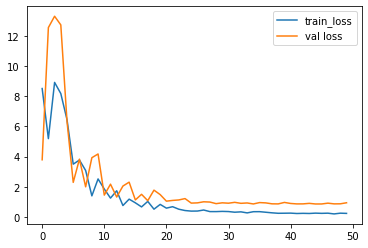

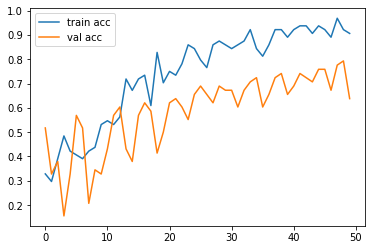

In [16]:
plt.plot(r.history["loss"],label='train_loss')
plt.plot(r.history['val_loss'],label='val loss')
plt.legend()
plt.show()
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend()
plt.show()

In [17]:
from tensorflow.keras.models import load_model

model.save('model_resnet50.h5')

In [18]:
y_pred=model.predict(test_set)

2/2 [==============================] - 20s 8s/step


In [19]:
y_pred

array([[2.70717889e-02, 6.20111585e-01, 3.52816612e-01],
       [4.31786990e-03, 9.55332041e-01, 4.03502025e-02],
       [5.16994409e-02, 6.09524190e-01, 3.38776350e-01],
       [1.31088207e-04, 9.83957648e-01, 1.59112550e-02],
       [9.29190874e-01, 3.01199704e-02, 4.06891517e-02],
       [8.57184269e-03, 1.44332170e-01, 8.47096026e-01],
       [2.28128191e-02, 4.27294731e-01, 5.49892485e-01],
       [7.55422283e-04, 6.53503597e-01, 3.45740974e-01],
       [1.16174640e-02, 5.72710276e-01, 4.15672332e-01],
       [1.35207009e-02, 9.12635624e-01, 7.38437623e-02],
       [1.16855882e-01, 3.64025295e-01, 5.19118786e-01],
       [8.71617794e-02, 5.98766387e-01, 3.14071834e-01],
       [1.43217975e-02, 3.44848514e-01, 6.40829682e-01],
       [3.71806584e-02, 7.48690307e-01, 2.14129031e-01],
       [6.39887992e-03, 8.77064764e-01, 1.16536275e-01],
       [5.96316590e-04, 9.38605785e-01, 6.07979074e-02],
       [2.35738908e-03, 4.27259654e-01, 5.70382953e-01],
       [3.16866930e-03, 9.95307

In [20]:
import numpy as np
y_pred=np.argmax(y_pred,axis=1)

In [22]:
len(y_pred)

58

In [23]:
y_pred

array([1, 1, 1, 1, 0, 2, 2, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 1, 2, 2, 2, 1,
       0, 0, 2, 2, 2, 2, 2, 1, 0, 2, 2, 2, 2, 1, 2, 2, 0, 1, 2, 0, 2, 2,
       2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 2, 1, 2, 2], dtype=int64)

In [24]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

In [26]:
model=load_model('model_resnet50.h5')

In [30]:
img=image.load_img('Datasets/Test/lamborghini/11.jpg',target_size=(224,224))

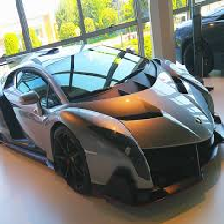

In [31]:
img

In [33]:
x=image.img_to_array(img)
x

array([[[252., 252., 252.],
        [252., 252., 252.],
        [252., 252., 252.],
        ...,
        [194., 188., 174.],
        [215., 209., 197.],
        [241., 235., 223.]],

       [[252., 252., 252.],
        [252., 252., 252.],
        [252., 252., 252.],
        ...,
        [247., 245., 233.],
        [245., 242., 233.],
        [244., 241., 232.]],

       [[252., 252., 252.],
        [252., 252., 252.],
        [252., 252., 252.],
        ...,
        [245., 248., 241.],
        [244., 250., 248.],
        [244., 250., 248.]],

       ...,

       [[190., 206., 229.],
        [190., 206., 229.],
        [190., 206., 229.],
        ...,
        [172., 179., 187.],
        [171., 180., 187.],
        [171., 180., 187.]],

       [[187., 205., 227.],
        [187., 205., 227.],
        [187., 205., 227.],
        ...,
        [172., 179., 187.],
        [171., 180., 187.],
        [171., 180., 187.]],

       [[185., 206., 227.],
        [185., 206., 227.],
        [187., 2

In [34]:
x.shape

(224, 224, 3)

In [35]:
x=x/255

In [36]:
x

array([[[0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        ...,
        [0.7607843 , 0.7372549 , 0.68235296],
        [0.84313726, 0.81960785, 0.77254903],
        [0.94509804, 0.92156863, 0.8745098 ]],

       [[0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        ...,
        [0.96862745, 0.9607843 , 0.9137255 ],
        [0.9607843 , 0.9490196 , 0.9137255 ],
        [0.95686275, 0.94509804, 0.9098039 ]],

       [[0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        [0.9882353 , 0.9882353 , 0.9882353 ],
        ...,
        [0.9607843 , 0.972549  , 0.94509804],
        [0.95686275, 0.98039216, 0.972549  ],
        [0.95686275, 0.98039216, 0.972549  ]],

       ...,

       [[0.74509805, 0.80784315, 0.8980392 ],
        [0.74509805, 0.80784315, 0.8980392 ],
        [0.74509805, 0

In [37]:
x=np.expand_dims(x,axis=0)
img_data=preprocess_input(x)
img_data.shape

(1, 224, 224, 3)

In [38]:
model.predict(img_data)

1/1 [==============================] - 2s 2s/step


array([[2.2418906e-03, 8.5886498e-04, 9.9689925e-01]], dtype=float32)

In [40]:
a=np.argmax(model.predict(img_data),axis=1)

1/1 [==============================] - 0s 193ms/step


In [41]:
a

array([2], dtype=int64)